In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load datasets
orders = pd.read_csv("../data/raw/olist_orders_dataset.csv")
items = pd.read_csv("../data/raw/olist_order_items_dataset.csv")

# Convert purchase timestamp
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"]
)

# Merge orders and items
sales = orders.merge(items, on="order_id", how="inner")

# Calculate revenue
sales["revenue"] = sales["price"]

# Extract month
sales["year_month"] = (
    sales["order_purchase_timestamp"].dt.to_period("M")
)

sales.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,revenue,year_month
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,29.99,2017-10
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76,118.70,2018-07
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22,159.90,2018-08
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20,45.00,2017-11
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72,19.90,2018-02


In [19]:
delivered_sales = sales[
    sales["order_status"] == "delivered"
].copy()

In [20]:
monthly_sales = (
    delivered_sales.groupby(
        delivered_sales['order_purchase_timestamp'].dt.to_period('M')
        ).agg(
            monthly_revenue = ("price" , "sum"),
            monthly_orders = ("order_id" , "nunique")
        )
)
print(monthly_sales.head(10))
print(monthly_sales.tail(10))

                          monthly_revenue  monthly_orders
order_purchase_timestamp                                 
2016-09                            134.97               1
2016-10                          40325.11             265
2016-12                             10.90               1
2017-01                         111798.36             750
2017-02                         234223.40            1653
2017-03                         359198.85            2546
2017-04                         340669.68            2303
2017-05                         489338.25            3546
2017-06                         421923.37            3135
2017-07                         481604.52            3872
                          monthly_revenue  monthly_orders
order_purchase_timestamp                                 
2017-11                         987765.37            7289
2017-12                         726033.19            5513
2018-01                         924645.00            7069
2018-02       

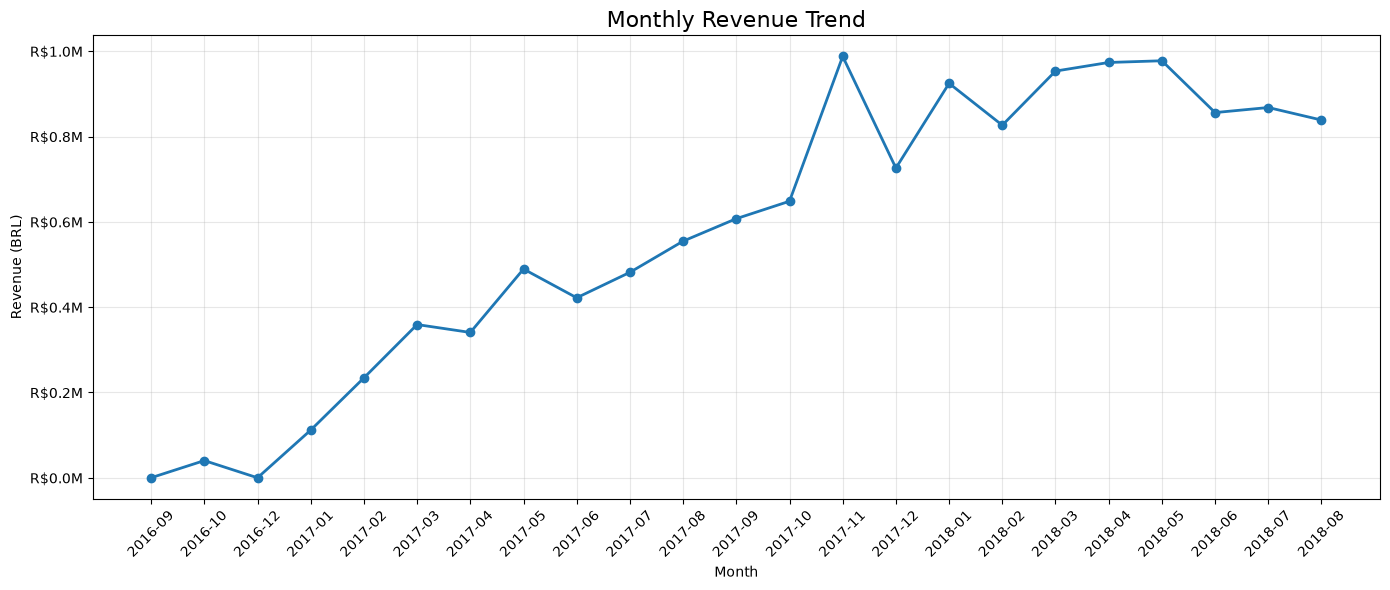

In [23]:
from matplotlib.ticker import FuncFormatter

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales["monthly_revenue"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Revenue Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Revenue (BRL)")

plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"R${x/1_000_000:.1f}M")
)

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

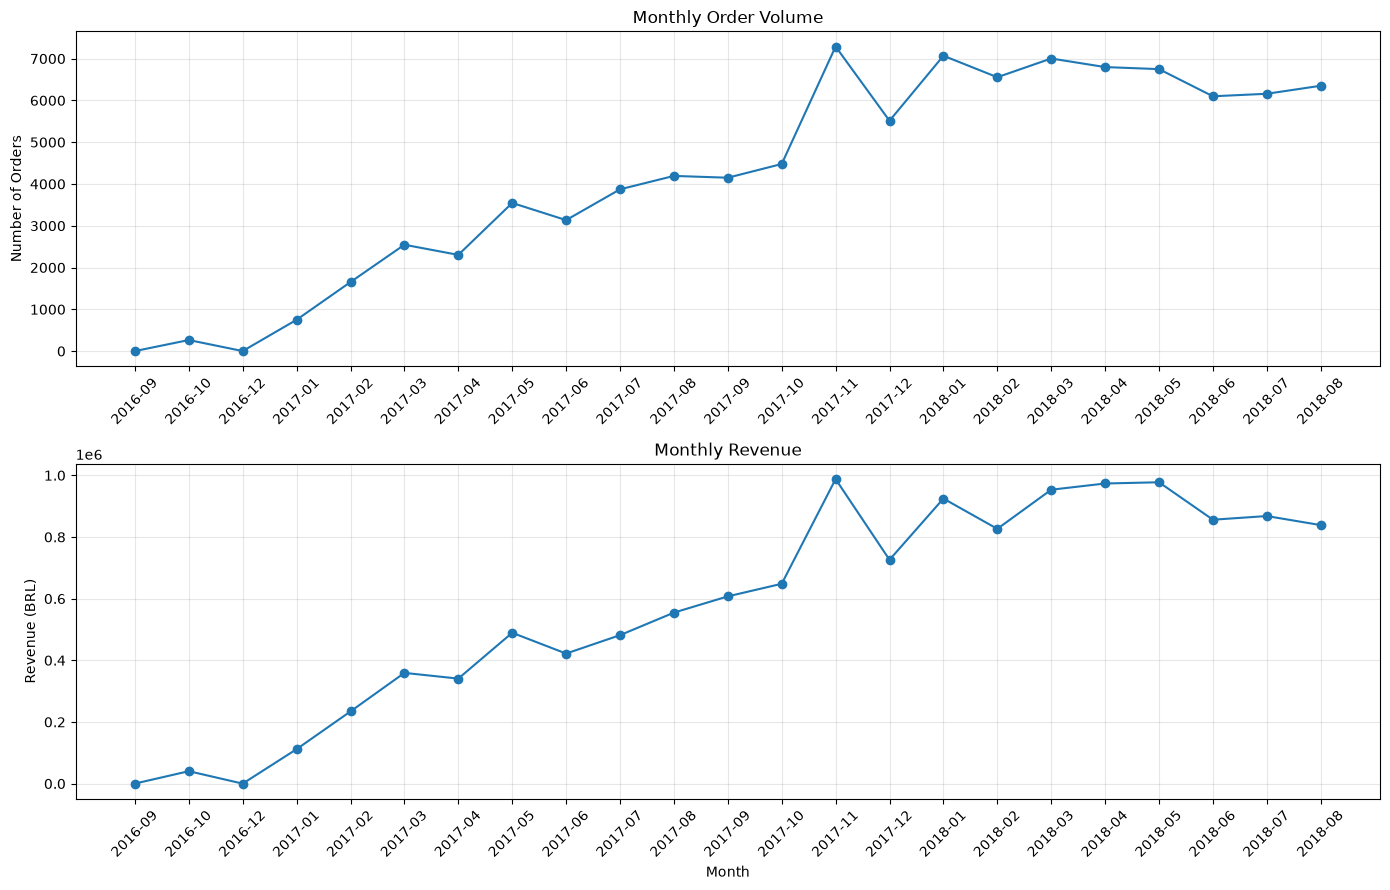

In [24]:
fig, ax = plt.subplots(2, 1, figsize=(14, 9))

# Chart 1: Monthly order volume
ax[0].plot(
    monthly_sales.index.astype(str),
    monthly_sales["monthly_orders"],
    marker="o"
)

ax[0].set_title("Monthly Order Volume")
ax[0].set_ylabel("Number of Orders")
ax[0].tick_params(axis="x", rotation=45)
ax[0].grid(True, alpha=0.3)

# Chart 2: Monthly revenue
ax[1].plot(
    monthly_sales.index.astype(str),
    monthly_sales["monthly_revenue"],
    marker="o"
)

ax[1].set_title("Monthly Revenue")
ax[1].set_ylabel("Revenue (BRL)")
ax[1].set_xlabel("Month")
ax[1].tick_params(axis="x", rotation=45)
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [28]:
monthly_sales["average_order_value"] = (
    # Your formula here
     monthly_sales['monthly_revenue']/monthly_sales['monthly_orders']
)

print(monthly_sales)

                          monthly_revenue  monthly_orders  average_order_value
order_purchase_timestamp                                                      
2016-09                            134.97               1           134.970000
2016-10                          40325.11             265           152.170226
2016-12                             10.90               1            10.900000
2017-01                         111798.36             750           149.064480
2017-02                         234223.40            1653           141.695947
2017-03                         359198.85            2546           141.083602
2017-04                         340669.68            2303           147.924307
2017-05                         489338.25            3546           137.997250
2017-06                         421923.37            3135           134.584807
2017-07                         481604.52            3872           124.381333
2017-08                         554699.70           

### Product Category Revenue Analysis

In [29]:
product  = pd.read_csv("../data/raw/olist_products_dataset.csv")
category = pd.read_csv("../data/raw/product_category_name_translation.csv")

In [48]:
delivered_orders = orders[orders['order_status'] == 'delivered'].copy()

In [39]:
delivered_items = items.merge(delivered_orders, on="order_id", how="inner")

In [49]:
product_sales = delivered_items.merge(product, on="product_id", how="left",validate="many_to_one")
product_sales = product_sales.merge(category, on="product_category_name", how="left",validate="many_to_one")

In [50]:
print(product_sales.shape)
print(product_sales.head())
print(product_sales["product_category_name_english"].isna().sum())

(110197, 23)
                           order_id  order_item_id  \
0  00010242fe8c5a6d1ba2dd792cb16214              1   
1  00018f77f2f0320c557190d7a144bdd3              1   
2  000229ec398224ef6ca0657da4fc703e              1   
3  00024acbcdf0a6daa1e931b038114c75              1   
4  00042b26cf59d7ce69dfabb4e55b4fd9              1   

                         product_id                         seller_id  \
0  4244733e06e7ecb4970a6e2683c13e61  48436dade18ac8b2bce089ec2a041202   
1  e5f2d52b802189ee658865ca93d83a8f  dd7ddc04e1b6c2c614352b383efe2d36   
2  c777355d18b72b67abbeef9df44fd0fd  5b51032eddd242adc84c38acab88f23d   
3  7634da152a4610f1595efa32f14722fc  9d7a1d34a5052409006425275ba1c2b4   
4  ac6c3623068f30de03045865e4e10089  df560393f3a51e74553ab94004ba5c87   

   shipping_limit_date   price  freight_value  \
0  2017-09-19 09:45:35   58.90          13.29   
1  2017-05-03 11:05:13  239.90          19.93   
2  2018-01-18 14:48:30  199.00          17.87   
3  2018-08-15 10:10:18   12

In [55]:
categorical_revenue = (
    product_sales.groupby(
        'product_category_name_english',
        dropna = False
    )
        .agg(
            total_revenue_category = ("price","sum"),
            total_orders = ('order_id' , 'nunique')
        )
)


In [54]:
categorical_revenue = categorical_revenue.sort_values(
    by="total_revenue_category",
    ascending=False
)

print(categorical_revenue.head(10))

                               total_revenue_category  total_orders
product_category_name_english                                      
health_beauty                              1233131.72          8647
watches_gifts                              1166176.98          5495
bed_bath_table                             1023434.76          9272
sports_leisure                              954852.55          7530
computers_accessories                       888724.61          6530
furniture_decor                             711927.69          6307
housewares                                  615628.69          5743
cool_stuff                                  610204.10          3559
auto                                        578966.65          3810
toys                                        471286.48          3804


In [56]:
# Check missing original categories
print(
    "Missing original categories:",
    product_sales["product_category_name"].isna().sum()
)

# Check categories without English translations
untranslated = product_sales[
    product_sales["product_category_name"].notna() &
    product_sales["product_category_name_english"].isna()
]

print(
    "Untranslated category rows:",
    len(untranslated)
)

print(
    untranslated["product_category_name"].value_counts()
)

Missing original categories: 1537
Untranslated category rows: 22
product_category_name
portateis_cozinha_e_preparadores_de_alimentos    14
pc_gamer                                          8
Name: count, dtype: int64


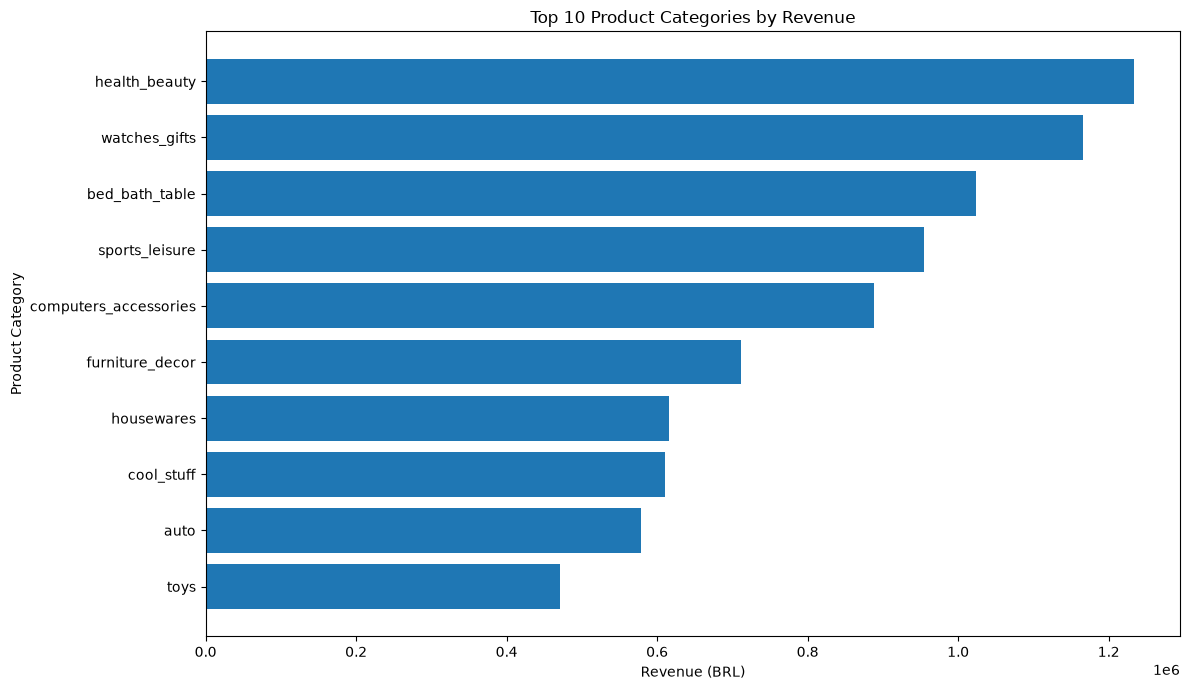

In [58]:
top_categories = (
    categorical_revenue
    .nlargest(10, "total_revenue_category")
    .sort_values("total_revenue_category", ascending=True)
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_categories.index.astype(str),
    top_categories["total_revenue_category"]
)

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Revenue (BRL)")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()